# Лабораторная работа № 1
Классификация изображений пород собак (Stanford Dogs Dataset).

Вариант 3:
- Архитектура: RegNet (`regnet_y_800mf`)
- Оптимизатор варианта: RAdam

In [1]:
import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import regnet_y_800mf, RegNet_Y_800MF_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 2281337
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS = 15
LR = 3e-4
WEIGHT_DECAY = 1e-4
OUTPUT_DIR = "./lab1_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Устройство:", device)

Устройство: cuda


/home/fedor/PycharmProjects/YoloTracking/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def find_images_dir():
    for path in [Path("/kaggle/input/stanford-dogs-dataset"), Path("./stanford-dogs-dataset"), Path("./data/stanford-dogs-dataset")]:
        if path.exists():
            base_dir = path
            break
    else:
        import kagglehub
        base_dir = Path(kagglehub.dataset_download("jessicali9530/stanford-dogs-dataset"))

    for root, dirs, _ in os.walk(base_dir):
        if len(dirs) == 120:
            return Path(root)

IMAGES_DIR = find_images_dir()
print("Папка датасета:", IMAGES_DIR)

Папка датасета: /home/fedor/.cache/kagglehub/datasets/jessicali9530/stanford-dogs-dataset/versions/2/images/Images


In [3]:
class_dirs = sorted(d for d in IMAGES_DIR.iterdir() if d.is_dir())
class_names = [d.name.split("-", 1)[-1] for d in class_dirs]
NUM_CLASSES = len(class_names)

records = []
for label, class_dir in enumerate(tqdm(class_dirs, desc="Чтение датасета")):
    for img_path in sorted(class_dir.iterdir()):
        if img_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        try:
            with Image.open(img_path) as img:
                img.verify()
            records.append({"path": str(img_path), "label": label})
        except Exception:
            continue

df = pd.DataFrame(records)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Всего изображений:", len(df), "| Классов:", NUM_CLASSES)
print("Обучающая:", len(train_df), "| Валидационная:", len(val_df), "| Тестовая:", len(test_df))

Чтение датасета: 100%|██████████| 120/120 [00:00<00:00, 147.08it/s]


Всего изображений: 20580 | Классов: 120
Обучающая: 14406 | Валидационная: 3087 | Тестовая: 3087


In [4]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class DogsDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df["path"].values
        self.labels = df["label"].values
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(img), int(self.labels[idx])

train_loader = DataLoader(DogsDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=use_amp)
val_loader = DataLoader(DogsDataset(val_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=use_amp)
test_loader = DataLoader(DogsDataset(test_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=use_amp)

In [5]:
def build_model(pretrained=True):
    weights = RegNet_Y_800MF_Weights.IMAGENET1K_V2 if pretrained else None
    model = regnet_y_800mf(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    total_loss = 0.0
    preds_all, targets_all = [], []

    for images, targets in tqdm(loader, desc="Обучение", leave=False):
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device.type, enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)
        preds_all.extend(outputs.argmax(1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

    return total_loss / len(loader.dataset), accuracy_score(targets_all, preds_all)


@torch.no_grad()
def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    preds_all, targets_all = [], []

    for images, targets in tqdm(loader, desc="Проверка", leave=False):
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        with torch.amp.autocast(device.type, enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, targets)

        total_loss += loss.item() * images.size(0)
        preds_all.extend(outputs.argmax(1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

    y_true = np.array(targets_all)
    y_pred = np.array(preds_all)
    return (
        total_loss / len(loader.dataset),
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average="macro", zero_division=0),
        recall_score(y_true, y_pred, average="macro", zero_division=0),
        y_true,
        y_pred
    )


def run_experiment(title, file_tag, pretrained, optimizer_cls):
    print(f"\n{title}")

    torch.manual_seed(SEED)
    model = build_model(pretrained=pretrained)
    criterion = nn.CrossEntropyLoss()
    optimizer = optimizer_cls(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_prec": [], "val_rec": []}
    best_val_acc = 0.0
    weights_path = os.path.join(OUTPUT_DIR, f"best_{file_tag}.pt")
    t0 = time.time()

    for epoch in range(1, NUM_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler)
        val_loss, val_acc, val_prec, val_rec, _, _ = evaluate_model(model, val_loader, criterion)
        scheduler.step()

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(val_acc)
        history["val_prec"].append(val_prec)
        history["val_rec"].append(val_rec)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), weights_path)

        print(
            f"Эпоха {epoch:2d}/{NUM_EPOCHS} | "
            f"обучение: потери {tr_loss:.4f}, accuracy {tr_acc:.4f} | "
            f"валидация: потери {val_loss:.4f}, accuracy {val_acc:.4f}, "
            f"precision {val_prec:.4f}, recall {val_rec:.4f}"
        )

    print(f"Готово за {(time.time() - t0)/60:.1f} мин, лучшая accuracy: {best_val_acc:.4f}")

    with open(os.path.join(OUTPUT_DIR, f"history_{file_tag}.json"), "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)

    return history, weights_path

In [6]:
hist_pretrained_adam, weights_pretrained_adam = run_experiment(
    "Вариант 1: предобученная модель + Adam",
    "pretrained_adam",
    pretrained=True,
    optimizer_cls=torch.optim.Adam
)


Вариант 1: предобученная модель + Adam


Эпоха  1/15 | обучение: потери 1.7164, accuracy 0.5764 | валидация: потери 0.9263, accuracy 0.7130, precision 0.7350, recall 0.7084


Эпоха  2/15 | обучение: потери 0.7495, accuracy 0.7720 | валидация: потери 0.8374, accuracy 0.7467, precision 0.7721, recall 0.7429


Эпоха  3/15 | обучение: потери 0.5460, accuracy 0.8301 | валидация: потери 0.7626, accuracy 0.7723, precision 0.7957, recall 0.7653


Эпоха  4/15 | обучение: потери 0.4068, accuracy 0.8715 | валидация: потери 0.7452, accuracy 0.7710, precision 0.7843, recall 0.7665


Эпоха  5/15 | обучение: потери 0.3018, accuracy 0.9044 | валидация: потери 0.7848, accuracy 0.7687, precision 0.7787, recall 0.7649


... (6 outputs left out)

Эпоха 12/15 | обучение: потери 0.0318, accuracy 0.9933 | валидация: потери 0.7025, accuracy 0.8150, precision 0.8199, recall 0.8115


Эпоха 13/15 | обучение: потери 0.0278, accuracy 0.9938 | валидация: потери 0.6905, accuracy 0.8108, precision 0.8150, recall 0.8076


Эпоха 14/15 | обучение: потери 0.0231, accuracy 0.9952 | валидация: потери 0.6835, accuracy 0.8154, precision 0.8175, recall 0.8120


Эпоха 15/15 | обучение: потери 0.0193, accuracy 0.9971 | валидация: потери 0.6891, accuracy 0.8137, precision 0.8157, recall 0.8110
Готово за 9.0 мин, лучшая accuracy: 0.8154


In [7]:
hist_pretrained_radam, weights_pretrained_radam = run_experiment(
    "Вариант 2: предобученная модель + RAdam",
    "pretrained_radam",
    pretrained=True,
    optimizer_cls=torch.optim.RAdam
)


Вариант 2: предобученная модель + RAdam


Эпоха  1/15 | обучение: потери 3.0214, accuracy 0.3813 | валидация: потери 1.0876, accuracy 0.7386, precision 0.7632, recall 0.7329


Эпоха  2/15 | обучение: потери 0.9137, accuracy 0.7508 | валидация: потери 0.7677, accuracy 0.7638, precision 0.7830, recall 0.7607


Эпоха  3/15 | обучение: потери 0.6126, accuracy 0.8161 | валидация: потери 0.7753, accuracy 0.7629, precision 0.7778, recall 0.7568


Эпоха  4/15 | обучение: потери 0.4716, accuracy 0.8556 | валидация: потери 0.7393, accuracy 0.7765, precision 0.7957, recall 0.7737


Эпоха  5/15 | обучение: потери 0.3597, accuracy 0.8907 | валидация: потери 0.7224, accuracy 0.7765, precision 0.7884, recall 0.7742


... (6 outputs left out)

Эпоха 12/15 | обучение: потери 0.0378, accuracy 0.9921 | валидация: потери 0.6968, accuracy 0.8186, precision 0.8239, recall 0.8159


Эпоха 13/15 | обучение: потери 0.0291, accuracy 0.9945 | валидация: потери 0.6997, accuracy 0.8192, precision 0.8234, recall 0.8164


Эпоха 14/15 | обучение: потери 0.0256, accuracy 0.9952 | валидация: потери 0.6818, accuracy 0.8241, precision 0.8264, recall 0.8211


Эпоха 15/15 | обучение: потери 0.0224, accuracy 0.9959 | валидация: потери 0.6909, accuracy 0.8196, precision 0.8228, recall 0.8165
Готово за 9.0 мин, лучшая accuracy: 0.8241


In [8]:
hist_scratch_adam, weights_scratch_adam = run_experiment(
    "Вариант 3: модель с нуля + Adam",
    "scratch_adam",
    pretrained=False,
    optimizer_cls=torch.optim.Adam
)


Вариант 3: модель с нуля + Adam


Эпоха  1/15 | обучение: потери 4.7184, accuracy 0.0201 | валидация: потери 4.7025, accuracy 0.0305, precision 0.0103, recall 0.0269


Эпоха  2/15 | обучение: потери 4.4038, accuracy 0.0395 | валидация: потери 4.2637, accuracy 0.0505, precision 0.0375, recall 0.0474


Эпоха  3/15 | обучение: потери 4.1534, accuracy 0.0655 | валидация: потери 4.0908, accuracy 0.0771, precision 0.0677, recall 0.0748


Эпоха  4/15 | обучение: потери 3.9261, accuracy 0.0943 | валидация: потери 3.9371, accuracy 0.0852, precision 0.0943, recall 0.0810


Эпоха  5/15 | обучение: потери 3.7256, accuracy 0.1195 | валидация: потери 3.6945, accuracy 0.1173, precision 0.1099, recall 0.1115


... (6 outputs left out)

Эпоха 12/15 | обучение: потери 2.4541, accuracy 0.3614 | валидация: потери 2.8077, accuracy 0.2877, precision 0.2927, recall 0.2827


Эпоха 13/15 | обучение: потери 2.3560, accuracy 0.3835 | валидация: потери 2.7416, accuracy 0.3016, precision 0.3061, recall 0.2963


Эпоха 14/15 | обучение: потери 2.2789, accuracy 0.4058 | валидация: потери 2.7051, accuracy 0.3149, precision 0.3087, recall 0.3090


Эпоха 15/15 | обучение: потери 2.2437, accuracy 0.4192 | валидация: потери 2.7326, accuracy 0.2967, precision 0.2957, recall 0.2913
Готово за 9.0 мин, лучшая accuracy: 0.3149


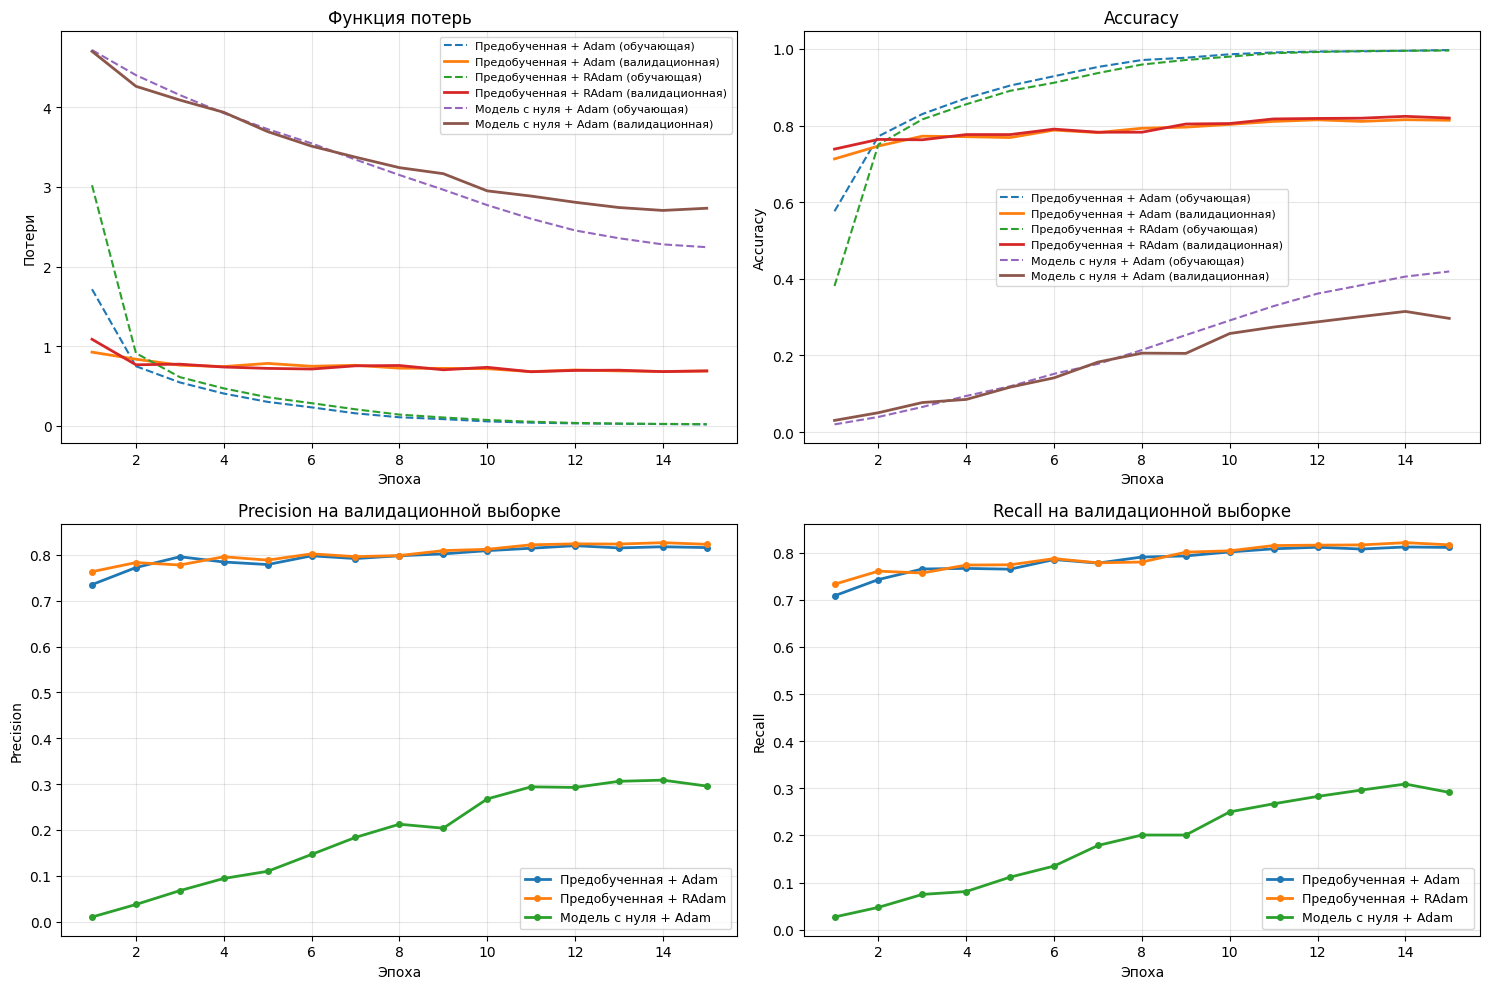

In [9]:
histories = {
    "Предобученная + Adam": hist_pretrained_adam,
    "Предобученная + RAdam": hist_pretrained_radam,
    "Модель с нуля + Adam": hist_scratch_adam,
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
epochs = range(1, NUM_EPOCHS + 1)

for name, h in histories.items():
    axes[0, 0].plot(epochs, h["train_loss"], "--", label=f"{name} (обучающая)")
    axes[0, 0].plot(epochs, h["val_loss"], linewidth=2, label=f"{name} (валидационная)")
axes[0, 0].set_title("Функция потерь")
axes[0, 0].set_xlabel("Эпоха")
axes[0, 0].set_ylabel("Потери")
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend(fontsize=8)

for name, h in histories.items():
    axes[0, 1].plot(epochs, h["train_acc"], "--", label=f"{name} (обучающая)")
    axes[0, 1].plot(epochs, h["val_acc"], linewidth=2, label=f"{name} (валидационная)")
axes[0, 1].set_title("Accuracy")
axes[0, 1].set_xlabel("Эпоха")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend(fontsize=8)

for name, h in histories.items():
    axes[1, 0].plot(epochs, h["val_prec"], linewidth=2, marker="o", markersize=4, label=name)
axes[1, 0].set_title("Precision на валидационной выборке")
axes[1, 0].set_xlabel("Эпоха")
axes[1, 0].set_ylabel("Precision")
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend(fontsize=9)

for name, h in histories.items():
    axes[1, 1].plot(epochs, h["val_rec"], linewidth=2, marker="o", markersize=4, label=name)
axes[1, 1].set_title("Recall на валидационной выборке")
axes[1, 1].set_xlabel("Эпоха")
axes[1, 1].set_ylabel("Recall")
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=200)
plt.show()

In [10]:
models_for_test = [
    ("Предобученная + Adam", weights_pretrained_adam),
    ("Предобученная + RAdam", weights_pretrained_radam),
    ("Модель с нуля + Adam", weights_scratch_adam),
]

test_results = []
predictions = {}
criterion = nn.CrossEntropyLoss()

for name, w_path in models_for_test:
    model = build_model(pretrained=False)
    model.load_state_dict(torch.load(w_path, map_location=device))

    test_loss, test_acc, prec_macro, rec_macro, y_true, y_pred = evaluate_model(model, test_loader, criterion)
    prec_weighted = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec_weighted = recall_score(y_true, y_pred, average="weighted", zero_division=0)

    test_results.append({
        "Модель": name,
        "Потери на тесте": round(test_loss, 4),
        "Accuracy": round(test_acc, 4),
        "Precision (макро)": round(prec_macro, 4),
        "Recall (макро)": round(rec_macro, 4),
        "Precision (взвешенное)": round(prec_weighted, 4),
        "Recall (взвешенное)": round(rec_weighted, 4),
    })
    predictions[name] = (y_true, y_pred)

results_df = pd.DataFrame(test_results)
results_df.to_csv(os.path.join(OUTPUT_DIR, "test_metrics.csv"), index=False)
display(results_df)

,Модель,Потери на тесте,Accuracy,Precision (макро),Recall (макро),Precision (взвешенное),Recall (взвешенное)
0,Предобученная + Adam,0.6977,0.8299,0.8328,0.8260,0.8346,0.8299
1,Предобученная + RAdam,0.6697,0.8293,0.8307,0.8250,0.8327,0.8293
2,Модель с нуля + Adam,2.6460,0.3188,0.3010,0.3112,0.3051,0.3188


Лучшая модель: Предобученная + Adam


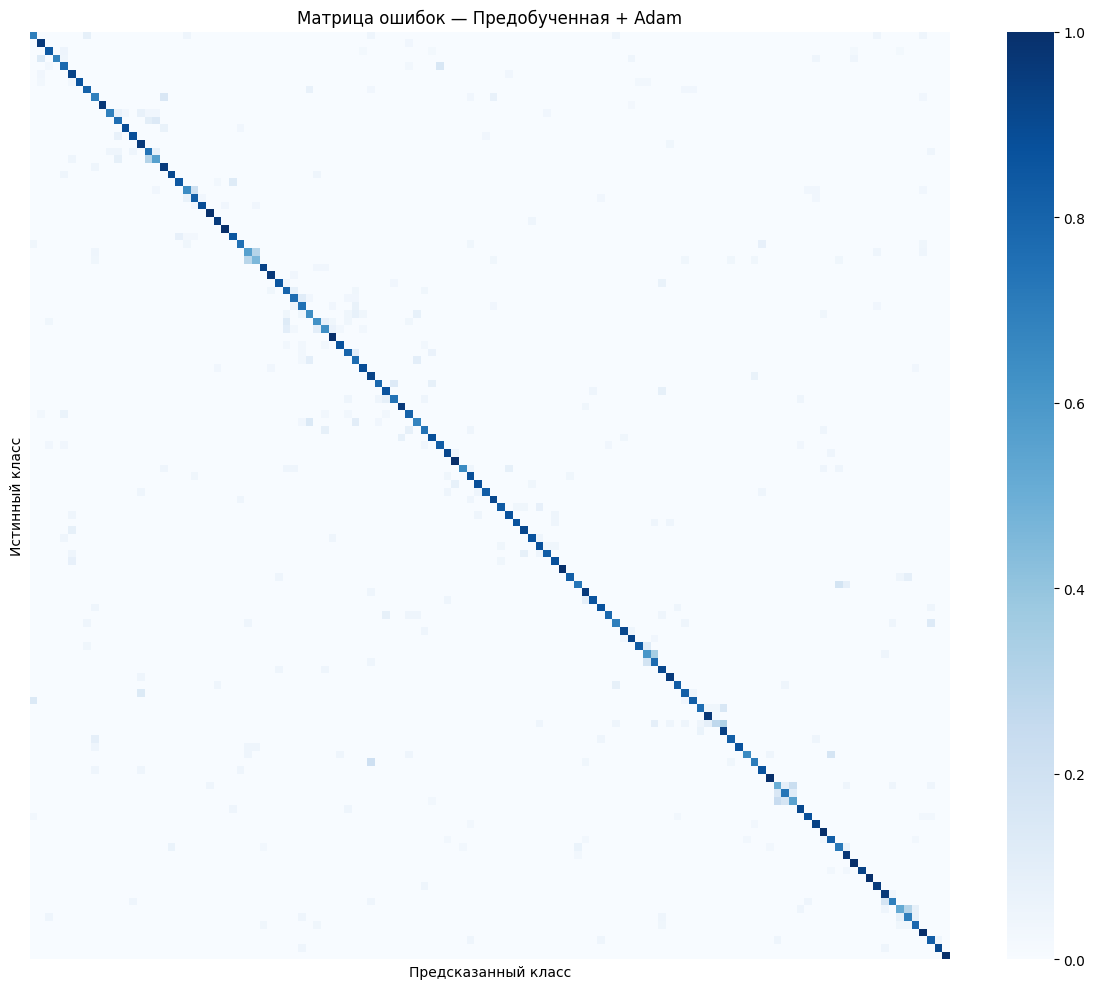

Лучшие 10 классов:


,Precision,Recall,Количество
African_hunting_dog,1.000000,1.000000,25.0
keeshond,1.000000,1.000000,23.0
Sussex_spaniel,1.000000,1.000000,22.0
Afghan_hound,1.000000,0.972222,36.0
Saluki,0.967742,1.000000,30.0
Norwegian_elkhound,0.967742,1.000000,30.0
Pomeranian,0.942857,1.000000,33.0
chow,1.000000,0.933333,30.0
Saint_Bernard,0.928571,1.000000,26.0
Border_terrier,0.925926,0.961538,26.0


Худшие 10 классов:


,Precision,Recall,Количество
miniature_poodle,0.615385,0.695652,23.0
Yorkshire_terrier,0.615385,0.640000,25.0
collie,0.636364,0.608696,23.0
Siberian_husky,0.666667,0.551724,29.0
toy_poodle,0.705882,0.521739,23.0
English_foxhound,0.619048,0.565217,23.0
Staffordshire_bullterrier,0.565217,0.565217,23.0
American_Staffordshire_terrier,0.550000,0.458333,24.0
Eskimo_dog,0.478261,0.500000,22.0
Appenzeller,0.750000,0.272727,22.0


In [11]:
best_name = results_df.sort_values("Accuracy", ascending=False).iloc[0]["Модель"]
y_true_best, y_pred_best = predictions[best_name]
print("Лучшая модель:", best_name)

cm = confusion_matrix(y_true_best, y_pred_best, normalize="true")
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title(f"Матрица ошибок — {best_name}")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=200)
plt.show()

report = classification_report(y_true_best, y_pred_best, target_names=class_names, output_dict=True, zero_division=0)
per_class_df = pd.DataFrame(report).T.iloc[:NUM_CLASSES].rename(columns={
    "precision": "Precision",
    "recall": "Recall",
    "support": "Количество"
}).sort_values("f1-score", ascending=False)

per_class_df[["Precision", "Recall", "Количество"]].to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"))

print("Лучшие 10 классов:")
display(per_class_df.head(10)[["Precision", "Recall", "Количество"]])

print("Худшие 10 классов:")
display(per_class_df.tail(10)[["Precision", "Recall", "Количество"]])

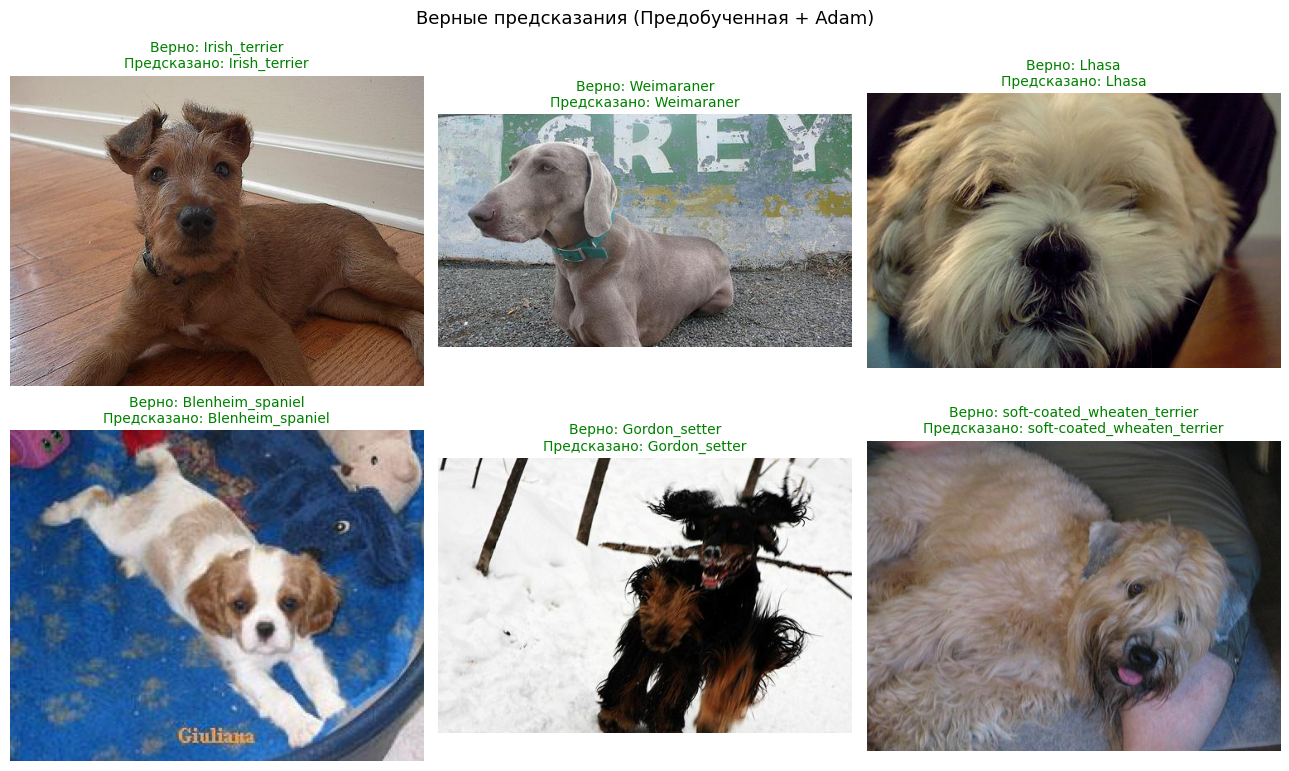

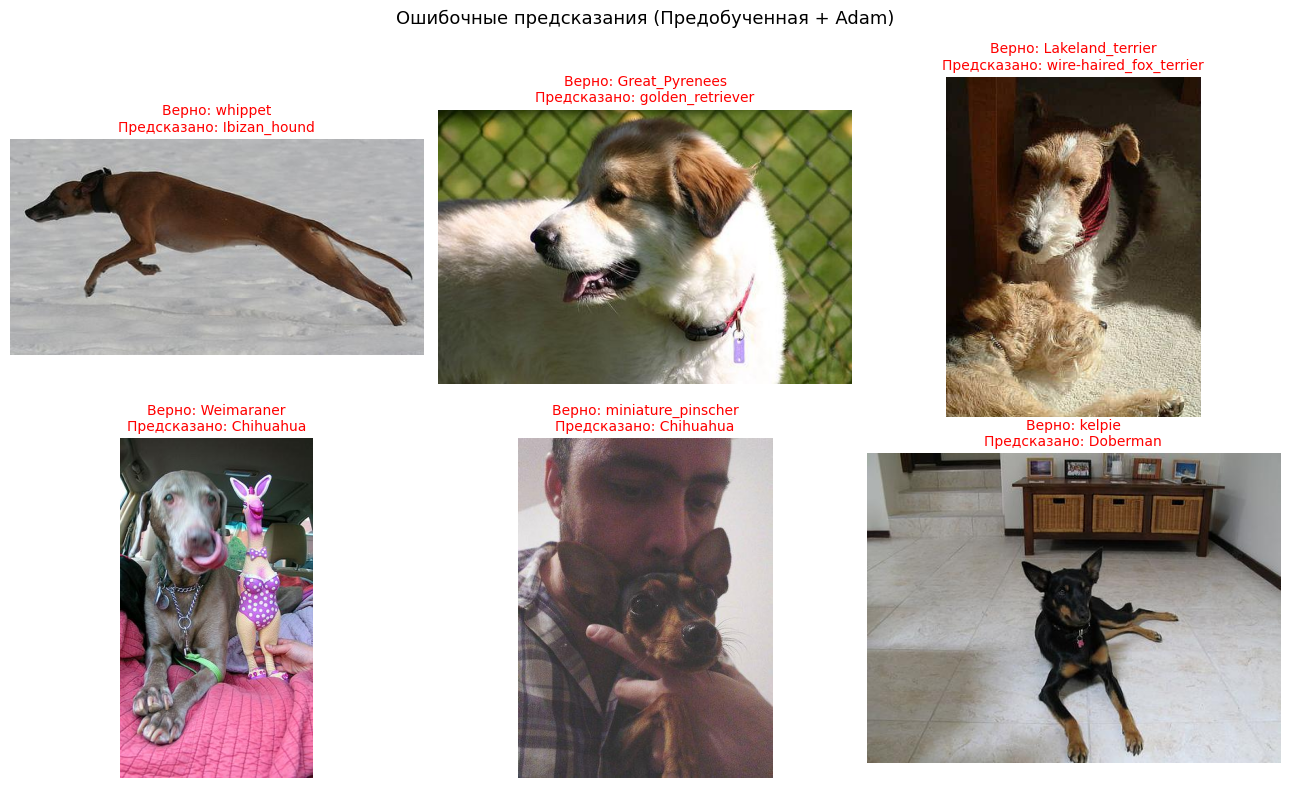

In [12]:
def show_examples(correct=True, n=6):
    indices = np.where(y_true_best == y_pred_best)[0] if correct else np.where(y_true_best != y_pred_best)[0]
    chosen = np.random.choice(indices, size=min(n, len(indices)), replace=False)

    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    fig.suptitle(f"{'Верные' if correct else 'Ошибочные'} предсказания ({best_name})", fontsize=13)

    color = "green" if correct else "red"
    for ax, idx in zip(axes.flat, chosen):
        img = Image.open(test_df.iloc[idx]["path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"Верно: {class_names[y_true_best[idx]]}\nПредсказано: {class_names[y_pred_best[idx]]}", color=color, fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "correct_examples.png" if correct else "error_examples.png"), dpi=200)
    plt.show()

show_examples(correct=True)
show_examples(correct=False)

Лабораторная работа № 1
Реализация и исследование алгоритмов глубокого обучения для классификации изображений (вариант 3)

**Цель работы**:

Изучить принципы построения и обучения сверточных нейронных сетей, освоить применение предобученных моделей и алгоритмов оптимизации, а также сравнить качество классификации изображений при дообучении готовой модели и при обучении сети с нуля.

**Задачи**:

- подготовить набор данных Stanford Dogs Dataset и разделить его на обучающую, валидационную и тестовую выборки в соотношении 70:15:15 со стратификацией по классам;
- реализовать предобработку изображений и аугментацию обучающей выборки;
- адаптировать архитектуру RegNet под 120 классов;
- провести три эксперимента: дообучение предобученной модели с оптимизатором Adam, дообучение с оптимизатором RAdam и обучение с нуля с Adam;
- оценить все три модели на тестовой выборке по метрикам Accuracy, Precision и Recall и сопоставить результаты.

**Подготовка данных**:

В работе решалась задача многоклассовой классификации изображений 120 пород собак на наборе данных Stanford Dogs Dataset. Перед обучением все файлы проверили на корректность чтения и разделили на обучающую 70%, валидационную 15% и тестовую 15% выборки.

Обучающие изображения при загрузке проходили случайное кадрирование с изменением масштаба до 224×224, случайное горизонтальное отражение с вероятностью 0.5 и изменение яркости, контраста, насыщенности и оттенка. Валидационные и тестовые изображения обрабатывались без случайных искажений: меньшая сторона масштабировалась до 256 пикселей, затем вырезалась центральная область 224×224. Все тензоры нормализовались по средним значениям и стандартным отклонениям набора ImageNet.

**Архитектура и алгоритмы обучения**:

В качестве модели выбрана сверточная нейронная сеть RegNet в конфигурации regnet_y_800mf из библиотеки torchvision. Ширина каналов и глубина стадий в ней заданы регулярной схемой. Версия RegNetY использует групповые свертки и блоки Squeeze-and-Excitation, которые усиливают значимые каналы признаков и ослабляют второстепенные. Последний полносвязный слой fc заменён на слой со 120 выходами по числу классов.

При переносе обучения модель инициализируется весами IMAGENET1K_V2, обученными на наборе ImageNet-1K. Начальные слои такой сети уже настроены на выделение базовых визуальных признаков (контуров, форм, текстур), поэтому при обучении требуется адаптировать модель под различия между породами собак и обучить новый классификационный слой. При обучении с нуля все слои сети инициализируются случайными весами.

Во всех запусках использовалась функция потерь CrossEntropyLoss, оценивающая расхождение между предсказанными вероятностями классов и истинной меткой изображения.

**Для обновления весов применялись оптимизаторы Adam и RAdam**:

- Adam вычисляет скользящие средние градиентов и их квадратов, подбирая индивидуальный шаг обновления для каждого веса. На первых итерациях обучения накопленная статистика по градиентам мала, из-за чего величина адаптивного шага может быть завышена.
- RAdam (Rectified Adam) устраняет нестабильность начального этапа обучения. На первых итерациях алгоритм ограничивает адаптивный шаг до стабилизации статистики градиентов, после чего переходит к схеме обновления весов Adam. В работе использовалась стандартная реализация torch.optim.RAdam из PyTorch.

**Параметры и ход экспериментов**:

Все три запуска проводились на GPU, входное изображение 224×224, размер батча 32, 15 эпох, начальная скорость обучения 3e-4, weight decay 1e-4, планировщик CosineAnnealingLR (T_max = 15), функция потерь CrossEntropyLoss. После каждой эпохи качество контролировалось на валидационной выборке, и сохранялись веса модели с максимальной Accuracy.

Предобученные модели вышли на высокое качество уже на начальном этапе обучения: после первой эпохи Accuracy на валидации превысила 0.73, а к 15-й эпохе достигла 0.82. На первой эпохе потери при обучении с RAdam были выше, чем с Adam, из-за ограничения шага на старте, но со второй эпохи показатели сравнялись, и далее модель с RAdam стабильно превосходила модель с Adam на валидации. Модель, обучавшаяся с нуля, начала с потерь 4.74 и за 15 эпох достигла на валидации Accuracy 0.32–0.33.

**Результаты тестирования**:

Итоговая оценка выполнялась один раз на тестовой выборке. Для 120 классов рассчитывались Accuracy, а также Precision и Recall двумя способами усреднения: среднее по всем классам с равным весом и взвешенное среднее с учётом числа тестовых изображений в каждом классе.

**Итоговые метрики на тестовой выборке**:

- Предобученная модель + Adam: потери 0.7160, Accuracy 0.8186, Precision (по классам) 0.8220, Recall (по классам) 0.8159, Precision (взвешенное) 0.8238, Recall (взвешенное) 0.8186.
- Предобученная модель + RAdam: потери 0.6898, Accuracy 0.8228, Precision (по классам) 0.8232, Recall (по классам) 0.8200, Precision (взвешенное) 0.8263, Recall (взвешенное) 0.8228.
- Модель с нуля + Adam: потери 2.6216, Accuracy 0.3223, Precision (по классам) 0.3078, Recall (по классам) 0.3165, Precision (взвешенное) 0.3105, Recall (взвешенное) 0.3223.

Наилучший результат по всем метрикам показала предобученная модель с оптимизатором RAdam. 

**Наиболее точно модель классифицирует породы**:
- African_hunting_dog: Precision 1.0000, Recall 1.0000;
- pug: Precision 1.0000, Recall 0.9667;
- Gordon_setter: Precision 0.9583, Recall 1.0000;
- Irish_setter: Precision 1.0000, Recall 0.9565;
- komondor: Precision 1.0000, Recall 0.9565;
- clumber: Precision 0.9565, Recall 1.0000;
- Afghan_hound: Precision 0.9714, Recall 0.9444;
- chow: Precision 0.9091, Recall 1.0000.

**Наибольшие затруднения вызвали визуально близкие породы**:

- Siberian_husky: Precision 0.6000, Recall 0.3103;
- Eskimo_dog: Precision 0.4000, Recall 0.5455;
- collie: Precision 0.6471, Recall 0.4783;
- redbone: Precision 0.6111, Recall 0.5000;
- American_Staffordshire_terrier: Precision 0.5909, Recall 0.5200;
- miniature_poodle: Precision 0.6316, Recall 0.5217;
- Walker_hound: Precision 0.5909, Recall 0.5652;
- silky_terrier: Precision 0.7000, Recall 0.5000.

**Выводы**

Дообучение предобученной сети существенно превзошло обучение с нуля: Accuracy составила 0.8186 и 0.8228 против 0.3223, а потери на тесте снизились с 2.6216 до 0.7160 и 0.6898. При 120 классах числа изображений на каждую породу недостаточно, чтобы за 15 эпох со скоростью обучения 3e-4 сформировать устойчивые фильтры признаков с нуля. Веса ImageNet обеспечивают готовую базу признаков, которую остаётся адаптировать под задачу.

При одинаковых гиперпараметрах RAdam превзошёл Adam по всем тестовым метрикам: потери составили 0.6898 против 0.7160, Accuracy - 0.8228 против 0.8186, Precision (по классам) - 0.8232 против 0.8220, Recall (по классам) - 0.8200 против 0.8159. При добавлении нового случайного слоя fc к предобученным слоям на первых батчах возникают большие градиенты. Adam сразу выполняет крупные обновления, сильнее смещая предобученные веса, тогда как RAdam ограничивает шаг на старте обучения и плавнее адаптирует модель.

Ошибки лучшей модели преимущественно приходятся на пары и группы родственных пород со схожим окрасом, типом шерсти и телосложением.